# Il segmento tecnologico in HS2007

*La rete del commercio dei minerali critici: struttura, vulnerabilità e prevedibilità lungo la filiera (1995–2024)*. Produce la **Tabella 6.4** e i numeri della **§6.1.6** (le dipendenze tecnologiche a valle), calcolati sulla release HS2007 di BACI.

È autonomo: non condivide variabili con `TESI_NOTEBOOK.ipynb` e scrive solo in `dati/OUT_BINARIO_C/`. Usa però le stesse unità geografiche e la stessa cartella dei dati. Va eseguito **dall'alto verso il basso**, nello stesso ambiente del notebook principale.

**Dati.** Serve solo `dati/BACI/BACI_HS07_V202601/`, che la cella *0. Download dei dati* del notebook principale scarica insieme alle altre revisioni.

| Tesi | Cella | Uscita |
|---|---|---|
| Tabella 6.4 | T6.4 | `dati/OUT_BINARIO_C/figure/tab_6_4_dipendenza_ue.png` |
| §6.1.6: importazioni 2024, indice di Herfindahl, primo fornitore | C11 | `ue_concentrazione.csv` |
| §6.1.6: quota cinese 2007 → 2024 su accumulatori e diodi, LED e fotovoltaico | C11 | `ue_dipendenza_annuale.csv` |

In [1]:
# %% CELLA C1 — configurazione autonoma
import re
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

import os

# Stessa cartella dei dati del notebook principale: la prima che contiene
# BACI/BACI_HS07_V202601 fra TESI_DATA_DIR, ./dati, ../dati, ~/dati,
# ~/Downloads/dati e ~/Downloads.
def _trova_dati():
    cand = [Path(os.environ["TESI_DATA_DIR"])] if os.environ.get("TESI_DATA_DIR") else []
    qui = Path.cwd()
    cand += [qui / "dati", qui.parent / "dati", qui, Path.home() / "dati",
             Path.home() / "Downloads" / "dati", Path.home() / "Downloads"]
    for c in cand:
        if (c.expanduser() / "BACI" / "BACI_HS07_V202601").is_dir():
            return c.expanduser().resolve()
    raise FileNotFoundError(
        "BACI/BACI_HS07_V202601 non trovata: eseguire prima la cella "
        "'0. Download dei dati' di TESI_NOTEBOOK.ipynb o impostare TESI_DATA_DIR.")


BASE = _trova_dati()
BACI = BASE / "BACI"
OUT_C = BASE / "OUT_BINARIO_C"; OUT_C.mkdir(exist_ok=True)
FIG_C = OUT_C / "figure"; FIG_C.mkdir(exist_ok=True)

REV = "HS07"
PRIMO_ANNO, ULTIMO_ANNO = 2007, 2024


def _leggi_country_codes():
    candidati = (list(BACI.glob(f"BACI_{REV}*/country_codes*.csv"))
                 + list(BASE.rglob("country_codes*.csv")))
    for p in candidati:
        cc = pd.read_csv(p, dtype=str, keep_default_na=False)
        cc.columns = [c.strip() for c in cc.columns]
        print(f"[CODICI] {p.name}")
        return cc
    raise FileNotFoundError("country_codes non trovato")


cc = _leggi_country_codes()
ISO = dict(zip(cc.country_code.astype(int), cc.country_iso3))
NAME = dict(zip(cc.country_code.astype(int), cc.country_name))

# Stesse unità geografiche del binario A (cella 3 del notebook principale):
# se le etichette là sono diverse, copiarle da lì.
MERGE_CODES = {56: 58, 442: 58,
               710: 711, 72: 711, 426: 711, 516: 711, 748: 711,
               16: 849, 316: 849,
               688: 891, 499: 891,
               531: 530, 534: 530, 535: 530,
               729: 736, 728: 736}
ISO.update({58: "BLX", 711: "SACU", 849: "PUS", 891: "SRB+MNE", 530: "ANT",
            736: "SDN+SSD", 490: "TWN"})
NAME.update({58: "Belgio-Lussemburgo", 711: "Unione doganale sudafricana",
             490: "Taiwan (Other Asia, nes)"})

CHN, HKG = 156, 344
print(f"dati: .../{BASE.name} | uscite: .../{BASE.name}/{OUT_C.name}")

[CODICI] country_codes_V202601.csv
dati: .../dati | uscite: .../dati/OUT_BINARIO_C


In [2]:
# %% CELLA C2 — individuazione della release e verifica dei codici
def scopri_release(rev=REV, base=None):
    base = base or BACI
    cart = next((c for c in list(base.glob(f"BACI_{rev}_V*")) + list(base.glob(f"*{rev}*"))
                 if c.is_dir()), None)
    if cart is None:
        raise FileNotFoundError(f"cartella BACI {rev} non trovata sotto {base}")
    anni = {int(m.group(1)): p for p in cart.glob(f"BACI_{rev}_Y*.csv")
            if (m := re.search(r"_Y(\d{4})_", p.name))}
    print(f"[{rev}] {cart.name}: {len(anni)} anni ({min(anni)}-{max(anni)})")
    return anni


ANNI = scopri_release()

# la voce 8542 è ristrutturata nel 2007: si verifica che i codici attesi
# contengano valore prima di costruire la serie
_d = pd.read_csv(ANNI[2015], usecols=["k", "v"], dtype={"k": str}, low_memory=False)
_d["k"] = _d.k.str.replace(r"\D", "", regex=True).str.zfill(6)
for voce in ["8542", "8507", "8541"]:
    s = _d[_d.k.str.startswith(voce)].groupby("k").v.sum().div(1e6)
    print(f"\n--- voce {voce}, 2015 (mld $) ---")
    print(s.sort_values(ascending=False).head(8).round(1).to_string())
del _d

[HS07] BACI_HS07_V202601: 18 anni (2007-2024)

--- voce 8542, 2015 (mld $) ---
k
854231    188.6
854239    183.7
854232    100.6
854290     18.9
854233      9.8

--- voce 8507, 2015 (mld $) ---
k
850780    17.5
850710     8.3
850720     6.6
850790     2.7
850730     0.9
850740     0.0

--- voce 8541, 2015 (mld $) ---
k
854140    54.7
854129    14.6
854110     9.2
854190     6.7
854160     6.6
854121     5.2
854150     3.1
854130     1.2


In [3]:
# %% CELLA C3 — dizionario del segmento tecnologico
# Codici stabili in HS2007, HS2012 e HS2017. Dove una revisione successiva
# introduce una sottovoce dedicata, la voce HS2007 resta aggregata.
TECH = {
    "854231": ("circuiti_integrati", "manufacturing"),
    "854232": ("circuiti_integrati", "manufacturing"),
    "854233": ("circuiti_integrati", "manufacturing"),
    "854239": ("circuiti_integrati", "manufacturing"),
    "854290": ("semiconduttori_parti", "manufacturing"),
    # in HS2007 gli accumulatori al litio ricadono in 850780 con altre chimiche;
    # il codice dedicato 850760 compare solo in HS2017
    "850780": ("accumulatori_altri", "manufacturing"),
    # 854140 aggrega celle fotovoltaiche, diodi e LED: le celle hanno un codice
    # autonomo solo in HS2022
    "854140": ("diodi_led_e_fotovoltaico", "manufacturing"),
    "854121": ("transistor", "manufacturing"),
    "854129": ("transistor", "manufacturing"),
    "850440": ("convertitori_statici", "manufacturing"),
    # escluso 854150: si svuota con la revisione HS2022 (3,53 mld nel 2021,
    # zero nel 2024), rilevato dal controllo di continuità della C5
}
ETICHETTE = {"circuiti_integrati": "Circuiti integrati",
             "semiconduttori_parti": "Parti di semiconduttori",
             "accumulatori_altri": "Accumulatori (litio e altre chimiche)",
             "diodi_led_e_fotovoltaico": "Diodi, LED e fotovoltaico",
             "transistor": "Transistor", "convertitori_statici": "Convertitori statici"}
print(f"[DIZ] {len(TECH)} codici, {len(set(v[0] for v in TECH.values()))} risorse")

[DIZ] 10 codici, 6 risorse


In [4]:
# %% CELLA C4 — costruzione del panel
def costruisci_binario_c(anni=None, diz=None, salva=True):
    """Panel annuale in codici HS2007 nativi, senza conversioni."""
    anni, diz = anni or sorted(ANNI), diz or TECH
    fuori = OUT_C / REV; fuori.mkdir(exist_ok=True)
    righe = []
    for y in anni:
        d = pd.read_csv(ANNI[y], usecols=["i", "j", "k", "v"], dtype={"k": str},
                        low_memory=False)
        d.columns = ["exp", "imp", "code", "value"]
        d["code"] = d.code.str.replace(r"\D", "", regex=True).str.zfill(6)
        d = d[d.code.isin(diz)]
        d["resource"] = d.code.map(lambda c: diz[c][0])
        d["stage_name"] = d.code.map(lambda c: diz[c][1])
        d["exp"] = d.exp.replace(MERGE_CODES)
        d["imp"] = d.imp.replace(MERGE_CODES)
        d = d[d.exp != d.imp]
        g = d.groupby(["exp", "imp", "resource", "stage_name"], as_index=False).value.sum()
        if salva:
            g.to_csv(fuori / f"binario_{REV}_{y}.csv", index=False)
        righe.append(dict(year=y, flussi=len(g), valore_mld=g.value.sum() / 1e6))
        print(f"  {y}: {len(g):,} flussi, {g.value.sum() / 1e6:,.0f} mld$")
    S = pd.DataFrame(righe)
    S.to_csv(OUT_C / f"sintesi_{REV}.csv", index=False)
    return S


SINT = costruisci_binario_c()

  2007: 26,929 flussi, 523 mld$
  2008: 30,617 flussi, 529 mld$
  2009: 33,116 flussi, 432 mld$
  2010: 34,520 flussi, 583 mld$
  2011: 35,472 flussi, 608 mld$
  2012: 36,530 flussi, 582 mld$
  2013: 37,410 flussi, 602 mld$
  2014: 37,843 flussi, 652 mld$
  2015: 39,323 flussi, 643 mld$
  2016: 39,421 flussi, 656 mld$
  2017: 40,181 flussi, 758 mld$
  2018: 40,352 flussi, 835 mld$
  2019: 40,805 flussi, 847 mld$
  2020: 39,671 flussi, 914 mld$
  2021: 41,348 flussi, 1,162 mld$
  2022: 41,357 flussi, 1,309 mld$
  2023: 41,501 flussi, 1,219 mld$
  2024: 39,204 flussi, 1,311 mld$


In [5]:
# %% CELLA C5 — caricamento, continuità e composizione
def carica_c(risorse=None, anni=None):
    parts = []
    for p in sorted((OUT_C / REV).glob(f"binario_{REV}_*.csv")):
        y = int(re.search(r"_(\d{4})\.csv", p.name).group(1))
        if anni and y not in anni:
            continue
        d = pd.read_csv(p)
        if risorse:
            d = d[d.resource.isin(risorse)]
        parts.append(d.assign(year=y))
    C = pd.concat(parts, ignore_index=True)
    print(f"[C] {len(C):,} osservazioni | {C.year.min()}-{C.year.max()} | "
          f"{C.value.sum() / 1e6:,.0f} mld$")
    return C


TC = carica_c()

V = TC.groupby(["resource", "year"]).value.sum().div(1e6).unstack()
RAPPORTO_2419 = (V[2024] / V[2019]).sort_values()
print("\ncontrollo di continuità, rapporto 2024/2019:\n" + RAPPORTO_2419.round(3).to_string())
_sosp = RAPPORTO_2419[(RAPPORTO_2419 < 0.5) | (RAPPORTO_2419 > 3)]
print(f"voci fuori dall'intervallo 0,5-3: "
      f"{_sosp.round(3).to_dict() if len(_sosp) else 'nessuna'}")
print("\ncomposizione (mld $):")
print(V.rename(index=ETICHETTE)[[2007, 2012, 2017, 2020, 2024]].round(0).to_string())

[C] 675,600 osservazioni | 2007-2024 | 14,165 mld$

controllo di continuità, rapporto 2024/2019:
resource
semiconduttori_parti        1.055
transistor                  1.330
diodi_led_e_fotovoltaico    1.383
circuiti_integrati          1.478
convertitori_statici        1.588
accumulatori_altri          3.536
voci fuori dall'intervallo 0,5-3: {'accumulatori_altri': 3.536}

composizione (mld $):
year                                    2007   2012   2017   2020   2024
resource                                                                
Accumulatori (litio e altre chimiche)   11.0   15.0   23.0   44.0  122.0
Circuiti integrati                     417.0  429.0  589.0  704.0  963.0
Convertitori statici                    35.0   47.0   53.0   63.0   94.0
Diodi, LED e fotovoltaico               26.0   54.0   52.0   57.0   77.0
Parti di semiconduttori                 16.0   19.0   18.0   21.0   22.0
Transistor                              18.0   18.0   22.0   24.0   33.0


In [6]:
# %% CELLA C8 — indice di Herfindahl
def hhi(s):
    s = np.asarray(s, float); s = s[s > 0]
    return float(((s / s.sum()) ** 2).sum()) if s.sum() > 0 else np.nan

In [7]:
# %% CELLA C10 — paesi dell'Unione europea
UE_ISO = {"DEU", "FRA", "ITA", "ESP", "NLD", "BLX", "AUT", "POL", "SWE", "CZE", "FIN",
          "PRT", "GRC", "HUN", "ROU", "BGR", "SVK", "SVN", "HRV", "DNK", "IRL", "EST",
          "LVA", "LTU", "MLT", "CYP"}
UE = {c for c, i in ISO.items() if i in UE_ISO}

In [ ]:
# %% CELLA C11 — approvvigionamento europeo
righe = []
for r in TC.resource.unique():
    d = TC[(TC.resource == r) & TC.imp.isin(UE) & ~TC.exp.isin(UE)]
    for y in sorted(d.year.unique()):
        g = d[d.year == y].groupby("exp").value.sum().sort_values(ascending=False)
        if g.empty:
            continue
        righe.append(dict(resource=r, risorsa=ETICHETTE.get(r, r), year=y,
                          import_mld=g.sum() / 1e6, hhi=hhi(g.values),
                          cr3=g.head(3).sum() / g.sum(),
                          primo=ISO.get(int(g.index[0]), g.index[0]),
                          quota_primo=g.iloc[0] / g.sum(),
                          quota_cina=(g.get(CHN, 0) + g.get(HKG, 0)) / g.sum()))
UEY = pd.DataFrame(righe)
UE_C = UEY[UEY.year.isin([2007, 2024])].copy()
UEY.to_csv(OUT_C / "ue_dipendenza_annuale.csv", index=False)
UE_C.to_csv(OUT_C / "ue_concentrazione.csv", index=False)
print(UE_C[UE_C.year == 2024].sort_values("import_mld", ascending=False)
      .round(3).to_string(index=False))
# numeri citati nella §6.1.6: quota della Cina (senza Hong Kong) sulle
# importazioni europee extra-UE, 2007 e 2024
for r in ["accumulatori_altri", "diodi_led_e_fotovoltaico"]:
    d = TC[(TC.resource == r) & TC.imp.isin(UE) & ~TC.exp.isin(UE)]
    tot = d.groupby("year").value.sum()
    cn = d[d.exp == CHN].groupby("year").value.sum()
    print(f"{ETICHETTE.get(r, r):40s} quota della Cina {cn[2007] / tot[2007]:.1%} (2007)"
          f" -> {cn[2024] / tot[2024]:.1%} (2024)")


In [9]:
# %% CELLA P4a — cornice delle tabelle, con ritorno a capo misurato
import textwrap

plt.rcParams.update(plt.rcParamsDefault)
FIG_DIR = FIG_C


def _car_per_pollice(corpo=10.0):
    if not hasattr(_car_per_pollice, "_cache"):
        fig = plt.figure(figsize=(4, 1))
        fig.canvas.draw()
        campione = "abcdefghijklmnopqrstuvwxyz ABCDEFGHIJKLMNOPQRSTUVWXYZ 0123456789"
        t = fig.text(0, 0, campione, fontsize=10.0)
        w = t.get_window_extent(renderer=fig.canvas.get_renderer()).width
        _car_per_pollice._cache = w / fig.dpi / len(campione)
        plt.close(fig)
    return _car_per_pollice._cache * corpo / 10.0


def _wrap_misurato(testo, corpo, larghezza_pollici):
    n = max(int(larghezza_pollici / _car_per_pollice(corpo)), 20)
    return "\n".join(textwrap.fill(p, n) for p in testo.split("\n"))


def _fill(testo, larghezza):
    """A capo che rispetta gli a capo espliciti e non spezza le parole:
    textwrap.fill tratta '\\n' come uno spazio e taglia le parole lunghe."""
    return "\n".join(textwrap.fill(p, larghezza, break_long_words=False,
                                    break_on_hyphens=False) or p
                      for p in str(testo).split("\n"))


def _anteprima(out):
    try:
        from PIL import Image
        im = Image.open(out).convert("RGBA")
        (Image.alpha_composite(Image.new("RGBA", im.size, "white"), im)
         .convert("RGB").save(out.with_name(out.stem + "_anteprima.png")))
    except ImportError:
        pass


def tabella(righe, colonne, larghezze, didascalia=None, nota=None, allinea=None,
            out=None, larghezza=9.5, fs=9.5, dpi=600, trasparente=True, anteprima=True):
    """Tabella in stile booktabs: tre filetti orizzontali, nessuna riga verticale."""
    assert abs(sum(larghezze) - 1) < 1e-6, f"le larghezze sommano a {sum(larghezze):.3f}"
    allinea = allinea or ["l"] * len(colonne)
    out = Path(out or (FIG_DIR / "tabella.png"))
    NERO, GRIGIO = "#000000", "#555555"
    H_RIGA, H_INT, H_DID = 0.30, 0.30, 0.26
    fs_did, fs_nt = fs - 0.5, fs - 2
    testi = [[_fill(v, max(int(w * larghezza * 10.5), 8))
              for v, w in zip(r, larghezze)] for r in righe]
    n_linee = [max(c.count("\n") + 1 for c in cel) for cel in testi]
    cols = [_fill(c, max(int(w * larghezza * 10.5), 8))
            for c, w in zip(colonne, larghezze)]
    n_int = max(c.count("\n") + 1 for c in cols)
    did = _wrap_misurato(didascalia, fs_did, larghezza) if didascalia else None
    nt = _wrap_misurato(nota, fs_nt, larghezza) if nota else None
    n_did = did.count("\n") + 1 if did else 0
    n_nt = nt.count("\n") + 1 if nt else 0
    altezza = (H_INT * n_int + sum(n * H_RIGA for n in n_linee) + 0.20
               + (0.14 + H_DID * n_did if did else 0) + (0.10 + (H_DID - 0.02) * n_nt if nt else 0))

    fig, ax = plt.subplots(figsize=(larghezza, altezza))
    ax.axis("off"); ax.set_xlim(0, 1); ax.set_ylim(0, altezza)
    y = altezza
    ax.plot([0, 1], [y, y], color=NERO, lw=1.1)
    y -= H_INT * n_int * 0.55
    x = 0
    for c, w, a in zip(cols, larghezze, allinea):
        ax.text(x + (w - 0.012 if a == "r" else 0.012), y, c, fontsize=fs, fontweight="bold",
                va="center", color=NERO, ha="right" if a == "r" else "left", linespacing=1.3)
        x += w
    y -= H_INT * n_int * 0.45
    ax.plot([0, 1], [y, y], color=NERO, lw=0.6)
    for cel, n in zip(testi, n_linee):
        y -= n * H_RIGA * 0.5
        x = 0
        for v, w, a in zip(cel, larghezze, allinea):
            ax.text(x + (w - 0.012 if a == "r" else 0.012), y, v, fontsize=fs, va="center",
                    color=NERO, ha="right" if a == "r" else "left", linespacing=1.35)
            x += w
        y -= n * H_RIGA * 0.5
    ax.plot([0, 1], [y, y], color=NERO, lw=1.1)
    if did:
        y -= 0.14 + H_DID * n_did * 0.5
        ax.text(0, y, did, fontsize=fs_did, va="center", color=NERO, linespacing=1.4)
        y -= H_DID * n_did * 0.5
    if nt:
        y -= 0.10 + (H_DID - 0.02) * n_nt * 0.5
        ax.text(0, y, nt, fontsize=fs_nt, color=GRIGIO, va="center", linespacing=1.4)
    fig.savefig(out, dpi=dpi, bbox_inches="tight", transparent=trasparente,
                facecolor="none" if trasparente else "white")
    plt.show(); plt.close(fig)
    if trasparente and anteprima:
        _anteprima(out)
    print(f"scritta {out.name}")
    return out

In [10]:
# %% CELLA P4b — cornice delle figure
def figura(disegna, didascalia=None, nota=None, out=None, larghezza=9.0, altezza=5.0,
           fs=9.5, dpi=600, margine_basso=0.55, margine_alto=0.15, margine_sx=0.95,
           margine_dx=0.25, trasparente=True, anteprima=True):
    NERO, GRIGIO = "#000000", "#555555"
    fs_did, fs_nt = fs - 0.5, fs - 2
    did = _wrap_misurato(didascalia, fs_did, larghezza) if didascalia else None
    nt = _wrap_misurato(nota, fs_nt, larghezza) if nota else None
    n_did = did.count("\n") + 1 if did else 0
    n_nt = nt.count("\n") + 1 if nt else 0
    H_DID, H_NT = 0.20, 0.17
    h_testi = ((0.12 + H_DID * n_did) if did else 0) + ((0.06 + H_NT * n_nt) if nt else 0)
    h_tot = margine_alto + altezza + margine_basso + h_testi
    fig = plt.figure(figsize=(larghezza, h_tot))
    ax = fig.add_axes([margine_sx / larghezza, (h_testi + margine_basso) / h_tot,
                       1 - (margine_sx + margine_dx) / larghezza, altezza / h_tot])
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.grid(alpha=0.25, lw=0.5)
    ax.tick_params(labelsize=fs - 1, colors=NERO)
    disegna(ax)
    x0, y = margine_sx / larghezza - 0.07, h_testi / h_tot
    if did:
        y -= 0.12 / h_tot
        fig.text(x0, y, did, fontsize=fs_did, color=NERO, va="top", linespacing=1.4)
        y -= H_DID * n_did / h_tot
    if nt:
        y -= 0.06 / h_tot
        fig.text(x0, y, nt, fontsize=fs_nt, color=GRIGIO, va="top", linespacing=1.4)
    out = Path(out or (FIG_DIR / "figura.png"))
    fig.savefig(out, dpi=dpi, bbox_inches="tight", transparent=trasparente,
                facecolor="none" if trasparente else "white")
    plt.show(); plt.close(fig)
    if trasparente and anteprima:
        _anteprima(out)
    print(f"scritta {out.name}")
    return out

In [11]:
# %% CELLA T6.0 — utilità per la tabella
ETI = {"circuiti_integrati": "Circuiti integrati", "accumulatori_altri": "Accumulatori",
       "convertitori_statici": "Convertitori statici",
       "diodi_led_e_fotovoltaico": "Diodi, LED e fotovoltaico",
       "semiconduttori_parti": "Parti di semiconduttori", "transistor": "Transistor"}
ORD_RIS = ["circuiti_integrati", "accumulatori_altri", "convertitori_statici",
           "diodi_led_e_fotovoltaico", "transistor", "semiconduttori_parti"]
ORD_BLOCCHI = ["Taiwan", "Corea", "Cina", "Sud-est asiatico", "Giappone", "Stati Uniti",
               "Unione europea", "Resto del mondo"]
NOMI_P8 = {"TWN": "Taiwan", "CHN": "Cina", "KOR": "Corea", "JPN": "Giappone",
           "USA": "Stati Uniti", "SGP": "Singapore", "MYS": "Malaysia", "HKG": "Hong Kong",
           "DEU": "Germania", "VNM": "Vietnam", "ISR": "Israele", "PHL": "Filippine",
           "THA": "Thailandia", "MEX": "Messico", "IND": "India", "CAN": "Canada",
           "GBR": "Regno Unito", "UE27": "Unione europea", "BRA": "Brasile",
           "IDN": "Indonesia", "CHE": "Svizzera", "CRI": "Costa Rica",
           "MAR": "Marocco", "AUS": "Australia"}
ANNI_T = [2007, 2012, 2017, 2020, 2024]
CINA_HK = "Cina con Hong Kong"


def _p8(x):
    return NOMI_P8.get(x, x)


def _min(s):
    """Minuscola solo sull'iniziale, così che le sigle (LED) restino intatte."""
    return s[:1].lower() + s[1:]


def _n(x, dec=3):
    if x is None or not np.isfinite(x):
        return "—"
    return f"{x:,.{dec}f}".replace(",", "\u00a0").replace(".", ",").replace("-", "−")


def _mig(x, dec=0):
    return f"{x:,.{dec}f}".replace(",", "\u00a0").replace("-", "−")


def _pp(x, dec=1):
    return _n(x, dec) + "%"


def _sgn(x, dec=3):
    if x is None or not np.isfinite(x):
        return "—"
    return f"{x:+.{dec}f}".replace(".", ",").replace("-", "−")


NOTA_ORIZZ = ("Fonte: elaborazione su BACI-CEPII, release HS2007 nativa. L'orizzonte è "
              "di diciotto anni: la nomenclatura del 1992 non contiene voci autonome per "
              "i semiconduttori, e la serie non è estendibile all'indietro.")

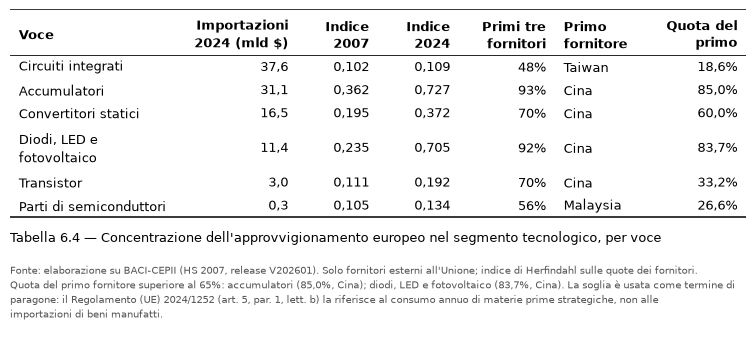

scritta tab_6_4_dipendenza_ue.png


In [12]:
# %% CELLA T6.4 — Tabella 6.4: concentrazione dell'approvvigionamento europeo
U24 = UE_C[UE_C.year == 2024].sort_values("import_mld", ascending=False)
U07 = UE_C[UE_C.year == 2007].set_index("resource")
_oltre = U24[U24.quota_primo >= 0.65]

tabella(
    [(ETI[r.resource], _n(r.import_mld, 1), _n(U07.loc[r.resource, "hhi"]), _n(r.hhi),
      _pp(r.cr3 * 100, 0), _p8(r.primo), _pp(r.quota_primo * 100)) for r in U24.itertuples()],
    ["Voce", "Importazioni\n2024 (mld $)", "Indice\n2007", "Indice\n2024",
     "Primi tre\nfornitori", "Primo\nfornitore", "Quota del\nprimo"],
    [0.24, 0.15, 0.11, 0.11, 0.13, 0.13, 0.13],
    didascalia="Tabella 6.4 — Concentrazione dell'approvvigionamento europeo nel segmento tecnologico, per voce",
    nota="Fonte: elaborazione su BACI-CEPII (HS 2007, release V202601). Solo fornitori esterni "
         "all'Unione; indice di Herfindahl sulle quote dei fornitori. "
         + (f"Quota del primo fornitore superiore al 65%: "
            + "; ".join(f"{_min(ETI[r.resource])} ({_pp(r.quota_primo * 100)}, "
                        f"{_p8(r.primo)})" for r in _oltre.itertuples()) + ". "
            "La soglia è usata come termine di paragone: il Regolamento (UE) 2024/1252 "
            "(art. 5, par. 1, lett. b) la riferisce al consumo annuo di materie prime "
            "strategiche, non alle importazioni di beni manufatti."
            if len(_oltre) else "Nessuna voce supera il 65%."),
    allinea=["l", "r", "r", "r", "r", "l", "r"],
    out=FIG_C / "tab_6_4_dipendenza_ue.png")